# Notebook 03 — The unscented Kalman filter

Companion to [Lecture 3](../03_state_estimation_ukf.md) (§2–§6). We build the same four-state UKF SAURCON
uses ($x, y, \psi, v$), drive it around a simulated track with a biased, noisy gyro, and test bias
calibration, pose fixes, gating (§5) and consistency. Figure 3.1 shows why the unscented transform is used.

In [1]:
import warnings; warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.color': '#e4e3df',
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'

## 1. Sigma points and weights (§3, equations 3.4–3.5)
With $n = 4$ and $\alpha = 0.1$ the central covariance weight is $W^c_0 \approx -96$. Lecture 3 §3 explains why
that is legal and how SAURCON's C++ filter keeps the covariance positive definite anyway (problem 3.2 probes the
boundary here).

In [2]:
def weights(n, alpha=0.1, beta=2.0, kappa=0.0):
    lam = alpha**2*(n + kappa) - n
    wm = np.full(2*n + 1, 1/(2*(n + lam))); wc = wm.copy()
    wm[0] = lam/(n + lam); wc[0] = wm[0] + 1 - alpha**2 + beta
    return lam, wm, wc

for a in (0.1, 0.5, 1.0):
    lam, wm, wc = weights(4, a)
    print(f"alpha={a}: W0m={wm[0]:8.2f}  W0c={wc[0]:8.2f}  Wi={wm[1]:.3f}")

alpha=0.1: W0m=  -99.00  W0c=  -96.01  Wi=12.500
alpha=0.5: W0m=   -3.00  W0c=   -0.25  Wi=0.500
alpha=1.0: W0m=    0.00  W0c=    2.00  Wi=0.125


## 2. The filter (Algorithm 3.1)

In [3]:
wrap = lambda a: np.arctan2(np.sin(a), np.cos(a))

class UKF:
    def __init__(self, x0, P0, q_xy=0.02, q_psi=1e-3, q_v=1e-2):
        self.x, self.P = np.array(x0, float), np.array(P0, float)
        self.q = (q_xy, q_psi, q_v); self.lam, self.wm, self.wc = weights(4)

    def sigma(self):
        S = np.linalg.cholesky((4 + self.lam)*(self.P + 1e-12*np.eye(4)))
        return np.column_stack([self.x] + [self.x + S[:, i] for i in range(4)] + [self.x - S[:, i] for i in range(4)])

    def predict(self, v, omega, dt):
        X = self.sigma(); Y = np.empty_like(X)
        for i in range(X.shape[1]):
            x, y, psi, _ = X[:, i]
            if abs(omega) > 1e-6:
                x += v/omega*(np.sin(psi + omega*dt) - np.sin(psi)); y += v/omega*(np.cos(psi) - np.cos(psi + omega*dt))
            else:
                x += v*np.cos(psi)*dt; y += v*np.sin(psi)*dt
            Y[:, i] = (x, y, psi + omega*dt, v)
        self.x = Y @ self.wm; self.x[2] = wrap(self.x[2])
        D = Y - self.x[:, None]; D[2] = wrap(D[2])
        q_xy, q_psi, q_v = self.q; s = q_xy*(1 + abs(v))
        self.P = (D*self.wc) @ D.T + np.diag([s*s*dt, s*s*dt, q_psi**2*dt, q_v**2*dt])

    def update(self, z, R, gate=25.0):
        X = self.sigma(); Z = X[:3]
        zh = Z @ self.wm
        dZ = Z - zh[:, None]; dZ[2] = wrap(dZ[2]); dX = X - self.x[:, None]; dX[2] = wrap(dX[2])
        S = (dZ*self.wc) @ dZ.T + R; Pxz = (dX*self.wc) @ dZ.T
        nu = z - zh; nu[2] = wrap(nu[2])
        d2 = nu @ np.linalg.solve(S, nu)
        if d2 > gate: return False                        # Mahalanobis gate: reject
        K = Pxz @ np.linalg.inv(S)
        self.x = self.x + K @ nu; self.x[2] = wrap(self.x[2]); self.P = self.P - K @ S @ K.T
        self.P = 0.5*(self.P + self.P.T)
        return True

## 3. A simulated drive
Stadium track at 2 m/s for 120 s. The gyro has a true bias of 0.002 rad/s and noise 0.009 rad/s per sample at
100 Hz (2.1); wheel speed has 2% noise. The car first sits still for 20 s.

In [4]:
rng = np.random.default_rng(3)
dt, T_park, T = 0.01, 20.0, 140.0
def truth_inputs(t):
    if t < T_park: return 0.0, 0.0
    s = (t - T_park)*2.0 % 47.57; v = 2.0
    on_bend = (17.5 <= s < 17.5 + 2*np.pi) or (s >= 35 + 2*np.pi)
    return v, (v/2.0 if on_bend else 0.0)
true_bias, sigma_g = 0.002, 0.009
N = int(T/dt); truth = np.zeros((N, 4)); meas = np.zeros((N, 2)); x = np.zeros(4)
for k in range(N):
    v, w = truth_inputs(k*dt)
    x = np.array([x[0] + v*np.cos(x[2])*dt, x[1] + v*np.sin(x[2])*dt, x[2] + w*dt, v]); truth[k] = x
    meas[k] = (v*(1 + rng.normal(0, 0.02)), w + true_bias + rng.normal(0, sigma_g))
print('lap length 47.6 m, laps driven:', round((T - T_park)*2/47.57, 2))

lap length 47.6 m, laps driven: 5.05


## 4. Dead reckoning: a 1 s bias calibration vs refining while parked (§7)

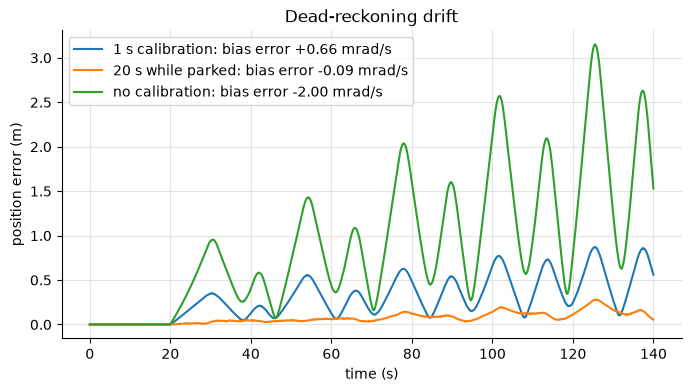

In [5]:
def dead_reckon(bias):
    f = UKF([0, 0, 0, 0], np.diag([1e-4, 1e-4, 1e-4, 1e-2])); out = []
    for k in range(N):
        v, w = meas[k]; f.predict(v, w - bias, dt); out.append(f.x.copy())
    return np.array(out)

b_short = meas[:100, 1].mean()                     # 100 samples = 1 s (the original code)
b_long = meas[:int(T_park/dt), 1].mean()           # every parked sample (the fix)
for name, b in (('1 s calibration', b_short), ('20 s while parked', b_long), ('no calibration', 0.0)):
    est = dead_reckon(b); err = np.hypot(*(est[:, :2] - truth[:, :2]).T)
    plt.plot(np.arange(N)*dt, err, label=f'{name}: bias error {1000*(b - true_bias):+.2f} mrad/s')
plt.xlabel('time (s)'); plt.ylabel('position error (m)'); plt.legend(); plt.title('Dead-reckoning drift'); plt.show()

## 5. Pose fixes at 2 Hz, with outliers, gating and consistency (§5)

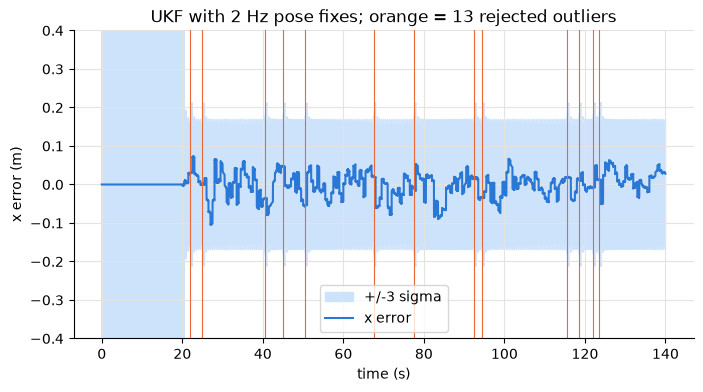

position RMS 0.043 m; 100.0% of x errors inside 3 sigma


In [6]:
f = UKF([0, 0, 0, 0], np.diag([0.04, 0.04, 1e-3, 1e-2])); R = np.diag([0.05**2, 0.05**2, 0.01**2])
est, sig, rejected = [], [], []
for k in range(N):
    v, w = meas[k]; f.predict(v, w - b_long, dt)
    if k % 50 == 0 and k*dt > T_park:
        z = truth[k, :3] + rng.normal(0, [0.05, 0.05, 0.01])
        if rng.random() < 0.05: z[:2] += rng.normal(0, 2.0, 2)          # 5% gross outliers
        if not f.update(z, R): rejected.append(k*dt)
    est.append(f.x.copy()); sig.append(np.sqrt(np.diag(f.P)))
est, sig = np.array(est), np.array(sig); tt = np.arange(N)*dt
ex = est[:, 0] - truth[:, 0]
plt.fill_between(tt, -3*sig[:, 0], 3*sig[:, 0], color='#cde2fb', label='+/-3 sigma')
plt.plot(tt, ex, color=BLUE, label='x error')
for r in rejected: plt.axvline(r, color=ORANGE, lw=0.8)
plt.ylim(-0.4, 0.4); plt.xlabel('time (s)'); plt.ylabel('x error (m)'); plt.legend()
plt.title(f'UKF with 2 Hz pose fixes; orange = {len(rejected)} rejected outliers'); plt.show()
inside = np.mean(np.abs(ex[tt > T_park]) < 3*sig[tt > T_park, 0])
print(f"position RMS {np.sqrt(np.mean(np.hypot(*(est[:, :2] - truth[:, :2]).T)**2)):.3f} m; "
      f"{100*inside:.1f}% of x errors inside 3 sigma")

## Problems
Lecture 3's problems **3.2**, **3.3** and **3.4** are done in this notebook.

**N3.1** Set `gate=1e9` (no gating). What happens to the error at each outlier?

**N3.2** Set the process noise `q_xy=0`. How quickly does the filter stop accepting fixes (the gating trap of §5)?

**N3.3** Delay each fix by 0.3 s before applying it, then implement the latency compensation (3.7) using the
odometry between the fix time and now. Compare both with problem 3.5's prediction.